# Manga Speech Balloon Detection & Translation — Manga109 Edition

End-to-end pipeline: manga page → U-Net segmentation → manga-ocr → translation.

**Architecture:** U-Net with VGG-16 encoder pretrained on ImageNet (Dubray & Laubrock, 2019)
**Dataset:** Manga109 images + MangaSeg pixel-level balloon masks (CVPR 2025)

---
**Every session checklist (in order):**
1. Runtime → Change runtime type → T4 GPU
2. Run **Step 0** (Drive mount)
3. Run **Step 1** (installs)
4. Run **Step 2** (all imports — fixes every NameError)
5. Then run whatever step you need

Steps 3–6 only need to run once ever. Steps 7+ can be run any time after 0–2.

## Step 0 — Mount Google Drive
Run this every session. Everything persists to Drive so nothing is lost on disconnect.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/manga_project'
MANGA109_DIR = f'{PROJECT_DIR}/manga109_images'
MANGSEG_DIR  = f'{PROJECT_DIR}/mangseg'
os.makedirs(PROJECT_DIR,   exist_ok=True)
os.makedirs(MANGA109_DIR,  exist_ok=True)
os.makedirs(MANGSEG_DIR,   exist_ok=True)
print('Drive mounted.')
print(f'Project dir: {PROJECT_DIR}')
print('Existing files in project dir:')
for f in sorted(os.listdir(PROJECT_DIR)):
    print(f'  {f}')


Mounted at /content/drive
Drive mounted.
Project dir: /content/drive/MyDrive/manga_project
Existing files in project dir:
  .cache
  Manga109_released_2023_12_07.zip
  manga109_best_model.pth
  manga109_checkpoint_epoch1.pth
  manga109_checkpoint_epoch10.pth
  manga109_checkpoint_epoch2.pth
  manga109_checkpoint_epoch3.pth
  manga109_checkpoint_epoch4.pth
  manga109_checkpoint_epoch5.pth
  manga109_checkpoint_epoch6.pth
  manga109_checkpoint_epoch7.pth
  manga109_checkpoint_epoch8.pth
  manga109_checkpoint_epoch9.pth
  manga109_data_exploration.png
  manga109_images
  manga109_loss_curve.png
  manga109_losses.json
  manga109_pages.json
  manga109_predictions.png
  mangseg
  test_images
  test_outputs
  test_translated


## Step 1 — Install dependencies
Run once per session. Takes ~2 minutes.
- `segmentation-models-pytorch` — U-Net with VGG-16 encoder
- `manga-ocr` — transformer OCR trained on manga fonts
- `deep-translator` — Google Translate wrapper, no API key needed
- `pycocotools` — decodes RLE masks from MangaSeg


In [2]:
!pip install -q segmentation-models-pytorch manga-ocr deep-translator pycocotools huggingface_hub datasets
print('Done!')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 MB 23.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 694.9/694.9 kB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.5 MB/s eta 0:00:00
Done!


## Step 2 — All imports
**Run this every session, right after installs.**
This single cell defines every import, helper function, and constant used by all later steps.
Running it fixes any NameError you might hit downstream.

In [6]:
import os, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image, ImageDraw
import cv2
import segmentation_models_pytorch as smp
from pycocotools import mask as mask_utils
from tqdm import tqdm

# ── Constants ──────────────────────────────────────────────────────────────
IMG_SIZE         = (512, 512)
BALLOON_CAT_ID   = 5          # category_id for 'balloon' in MangaSeg
BATCH_SIZE       = 8
NUM_EPOCHS       = 10
LEARNING_RATE    = 1e-4
THRESHOLD        = 0.5
MIN_BALLOON_AREA = 1000       # pixels — ignore smaller detections as noise

PROJECT_DIR  = '/content/drive/MyDrive/manga_project'
MANGA109_DIR = f'{PROJECT_DIR}/manga109_images'
MANGSEG_DIR  = f'{PROJECT_DIR}/mangseg'
CHECKPOINT   = f'{PROJECT_DIR}/manga109_best_model.pth'  # separate from mantra model!

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')
if device == 'cpu':
    print('WARNING: No GPU! Go to Runtime → Change runtime type → T4 GPU')

# ── Image transform ────────────────────────────────────────────────────────
img_transform = T.Compose([
    T.Resize(IMG_SIZE),
    T.ToTensor(),
    T.Normalize([0.5], [0.5])
])

# ── Helper: build mask from bounding boxes ─────────────────────────────────
def make_mask_from_boxes(img_size, boxes):
    mask = Image.new('L', img_size, 0)
    draw = ImageDraw.Draw(mask)
    for b in boxes:
        draw.rectangle([b['x'], b['y'], b['x']+b['w'], b['y']+b['h']], fill=255)
    return mask

# ── Helper: build mask from RLE (MangaSeg format) ──────────────────────────
def make_mask_from_rle(annotations, img_h, img_w):
    combined = np.zeros((img_h, img_w), dtype=np.uint8)
    for ann in annotations:
        if ann['category_id'] in (2, 5):  # text + balloon
            rle = ann['segmentation']
            decoded = mask_utils.decode(rle)
            combined = np.maximum(combined, decoded)
    return combined

# ── Dataset class ──────────────────────────────────────────────────────────
class MangaDataset(Dataset):
    def __init__(self, page_list):
        self.pages = page_list

    def __len__(self):
        return len(self.pages)

    def __getitem__(self, idx):
        page = self.pages[idx]
        img = Image.open(page['img_path']).convert('L')
        img_tensor = img_transform(img)

        # Decode RLE mask on the fly instead of precomputing
        mask = make_mask_from_rle(page['annotations'], page['img_h'], page['img_w'])
        mask_pil = Image.fromarray(mask * 255)
        mask_pil = mask_pil.resize(IMG_SIZE, Image.NEAREST)
        mask_tensor = torch.tensor(
            np.array(mask_pil) / 255.0, dtype=torch.float32
        ).unsqueeze(0)

        return img_tensor, mask_tensor

# ── Model factory ──────────────────────────────────────────────────────────
def build_model():
    m = smp.Unet(
        encoder_name='vgg16',
        encoder_weights='imagenet',
        in_channels=1,
        classes=1
    ).to(device)
    return m

# ── Dice loss ──────────────────────────────────────────────────────────────
class DiceLoss(nn.Module):
    def forward(self, pred, target, smooth=1):
        pred = torch.sigmoid(pred).view(-1)
        target = target.view(-1)
        intersection = (pred * target).sum()
        return 1 - (2*intersection + smooth) / (pred.sum() + target.sum() + smooth)

# ── F1 evaluation ──────────────────────────────────────────────────────────
def compute_f1(model, loader, threshold=THRESHOLD):
    model.eval()
    tp = fp = fn = 0
    with torch.no_grad():
        for img, mask in tqdm(loader, desc='Evaluating'):
            img, mask = img.to(device), mask.to(device)
            pred = torch.sigmoid(model(img))
            pred_bin = (pred > threshold).float()
            tp += (pred_bin * mask).sum().item()
            fp += (pred_bin * (1 - mask)).sum().item()
            fn += ((1 - pred_bin) * mask).sum().item()
    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    f1        = 2*precision*recall / (precision + recall + 1e-8)
    print(f'Threshold {threshold:.2f} | Precision {precision:.4f} | Recall {recall:.4f} | F1 {f1:.4f}')
    return f1

# ── Inference pipeline ─────────────────────────────────────────────────────
def run_pipeline(pil_image, model, threshold=THRESHOLD, min_area=MIN_BALLOON_AREA):
    """Raw manga PIL image → annotated PIL image with bounding boxes."""
    orig_w, orig_h = pil_image.size
    img_gray = pil_image.convert('L')
    img_tensor = img_transform(img_gray).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        pred = torch.sigmoid(model(img_tensor))

    mask = (pred.squeeze().cpu().numpy() > threshold).astype(np.uint8) * 255
    mask = cv2.resize(mask, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_cv = cv2.cvtColor(np.array(pil_image.convert('RGB')), cv2.COLOR_RGB2BGR)
    boxes_found = []

    # for cnt in contours:
    #     if cv2.contourArea(cnt) < min_area:
    #         continue
    #     x, y, w, h = cv2.boundingRect(cnt)
    #     cv2.rectangle(img_cv, (x, y), (x+w, y+h), (0, 200, 0), 2)
    #     boxes_found.append((x, y, w, h))

    for cnt in contours:
      if cv2.contourArea(cnt) < min_area:
          continue
      # Draw the actual predicted contour shape instead of a bounding box
      cv2.drawContours(img_cv, [cnt], -1, (0, 200, 0), 4)
      boxes_found.append(cv2.boundingRect(cnt))

    return Image.fromarray(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)), boxes_found

print('All imports and helpers ready!')
print(f'Checkpoint will save to: {CHECKPOINT}')


Device: cuda
All imports and helpers ready!
Checkpoint will save to: /content/drive/MyDrive/manga_project/manga109_best_model.pth


## Step 3 — Download datasets (run once ever)
Downloads Manga109 images and MangaSeg annotations to Drive.
Skips automatically if already downloaded.

You need HuggingFace access to both:
- `hal-utokyo/Manga109`
- `MS92/MangaSegmentation`

In [ ]:
from huggingface_hub import login, snapshot_download, hf_hub_download
login()  # paste your HuggingFace token


In [ ]:
from datasets import load_dataset, load_from_disk
import zipfile

# ── MangaSeg (annotations) ─────────────────────────────────────────────────
if not os.path.exists(f'{MANGSEG_DIR}/done.flag'):
    print('Downloading MangaSeg...')
    seg_ds = load_dataset('MS92/MangaSegmentation')
    seg_ds.save_to_disk(MANGSEG_DIR)
    open(f'{MANGSEG_DIR}/done.flag', 'w').close()
    print('MangaSeg saved to Drive.')
else:
    print('MangaSeg already on Drive, skipping.')

# ── Manga109 (images via zip) ──────────────────────────────────────────────
MANGA109_EXTRACTED = f'{MANGA109_DIR}/Manga109_released_2023_12_07'

if not os.path.exists(f'{MANGA109_DIR}/done.flag'):
    print('Downloading Manga109 zip (~4GB, takes a few minutes)...')
    zip_path = hf_hub_download(
        repo_id='hal-utokyo/Manga109',
        filename='Manga109_released_2023_12_07.zip',
        repo_type='dataset',
        local_dir=PROJECT_DIR
    )
    print('Extracting...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(MANGA109_DIR)
    open(f'{MANGA109_DIR}/done.flag', 'w').close()
    print('Manga109 saved to Drive.')
else:
    print('Manga109 already on Drive, skipping.')

# ── Verify both are ready ──────────────────────────────────────────────────
assert os.path.exists(f'{MANGSEG_DIR}/done.flag'), 'MangaSeg not ready!'
assert os.path.exists(f'{MANGA109_DIR}/done.flag'), 'Manga109 not ready!'
print('Both datasets ready. Proceed to Step 4.')

README.md:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/109 [00:00<?, ?it/s]

ARMS.json:   0%|          | 0.00/2.87M [00:00<?, ?B/s]

ByebyeC-BOY.json:   0%|          | 0.00/5.38M [00:00<?, ?B/s]

AosugiruHaru.json:   0%|          | 0.00/3.98M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/109 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/109 [00:00<?, ? examples/s]

MangaSeg saved to Drive.


Manga109_released_2023_12_07.zip:   0%|          | 0.00/4.11G [00:00<?, ?B/s]

Extracting...
Manga109 saved to Drive.
Both datasets ready. Proceed to Step 4.


## Step 4 — Build page list and explore data (run once ever)
Joins Manga109 images with MangaSeg masks and saves the result to Drive.
After this runs once, Step 5 loads directly from the saved file.

In [ ]:
from datasets import load_from_disk

PAGES_CACHE = f'{PROJECT_DIR}/manga109_pages.json'
IMAGES_DIR  = f'{MANGA109_DIR}/Manga109_released_2023_12_07/images'

if not os.path.exists(PAGES_CACHE):
    print('Building page list from MangaSeg + Manga109...')
    seg_ds = load_from_disk(MANGSEG_DIR)

    pages = []
    missing = 0

    # Loop over all 109 series entries
    for entry in seg_ds['train']:
        id_to_meta = {img['id']: img for img in entry['images']}
        id_to_anns = {}
        for ann in entry['annotations']:
            id_to_anns.setdefault(ann['image_id'], []).append(ann)

        for img_id, meta in id_to_meta.items():
            balloon_anns = [a for a in id_to_anns.get(img_id, [])
                            if a['category_id'] in (2, 5)]
            if not balloon_anns:
                continue
            img_path = f"{IMAGES_DIR}/{meta['file_name']}"
            if not os.path.exists(img_path):
                missing += 1
                continue
            pages.append({
                'img_path': img_path,
                'img_h': meta['height'],
                'img_w': meta['width'],
                'annotations': balloon_anns
            })

    with open(PAGES_CACHE, 'w') as f:
        json.dump(pages, f)
    print(f'Built {len(pages)} pages, {missing} missing. Saved to Drive.')
else:
    print(f'Already built at {PAGES_CACHE}, skip to Step 5.')

Building page list from MangaSeg + Manga109...
Built 10043 pages, 0 missing. Saved to Drive.


## Step 5 — Load pages and build dataloaders
**Run this every session after Step 2.**
Loads the cached page list from Drive and builds train/val splits.
Takes seconds — no re-downloading.

In [4]:
PAGES_CACHE = f'{PROJECT_DIR}/manga109_pages.json'

with open(PAGES_CACHE) as f:
    raw_pages = json.load(f)

# Don't precompute masks — decode RLE on the fly in __getitem__
random.seed(42)
random.shuffle(raw_pages)
split = int(len(raw_pages) * 0.8)
train_pages = raw_pages[:split]
val_pages   = raw_pages[split:]

print(f'Total pages: {len(raw_pages)}')
print(f'Train: {len(train_pages)} | Val: {len(val_pages)}')

train_ds = MangaDataset(train_pages)
val_ds   = MangaDataset(val_pages)
trainloader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
valloader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print('Dataloaders ready!')

Total pages: 10043
Train: 8034 | Val: 2009
Dataloaders ready!


## Step 6 — Visualize data (optional, run once to sanity check)
Confirm images load correctly and pixel masks look right before training.

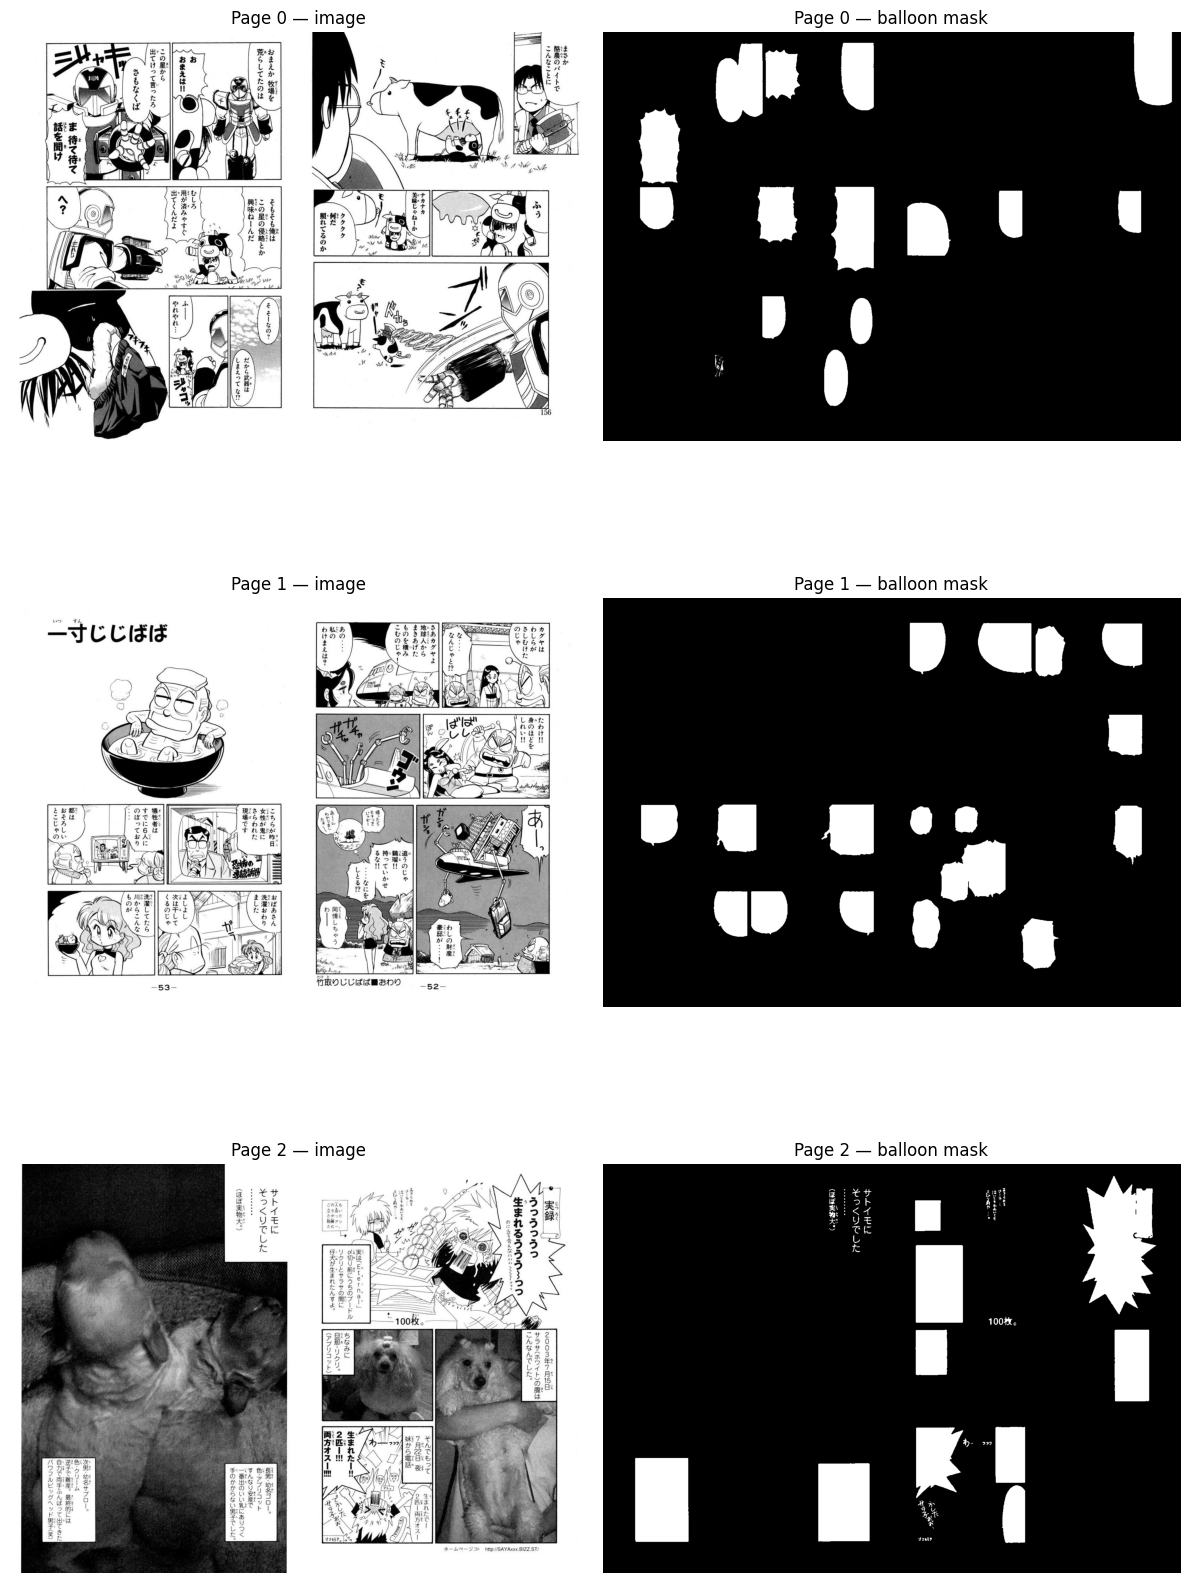

Saved to Drive.


In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 18))
for i in range(3):
    page = val_pages[i]
    img  = Image.open(page['img_path']).convert('L')
    mask = make_mask_from_rle(page['annotations'], page['img_h'], page['img_w'])

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'Page {i} — image')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask, cmap='gray')
    axes[i, 1].set_title(f'Page {i} — balloon mask')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/manga109_data_exploration.png', dpi=100)
plt.show()
print('Saved to Drive.')

## Step 7 — Build model
**Run every session after Step 2.**
Builds the U-Net. If a checkpoint exists on Drive, loads it automatically.

In [5]:
model = build_model()

if os.path.exists(CHECKPOINT):
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
    print(f'Loaded checkpoint from {CHECKPOINT}')
    print('Skip to Step 9 (eval) or Step 10 (inference) if already trained.')
else:
    print('No checkpoint found — starting from scratch.')
    print('Run Step 8 to train.')

total = sum(p.numel() for p in model.parameters())
print(f'Model parameters: {total:,}')


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/553M [00:00<?, ?B/s]

Loaded checkpoint from /content/drive/MyDrive/manga_project/manga109_best_model.pth
Skip to Step 9 (eval) or Step 10 (inference) if already trained.
Model parameters: 23,747,089


## Step 8 — Train
Only run this if you have no checkpoint yet, or want to retrain.
Expected time: ~2-3 hours for 30 epochs on T4 GPU.
Best model saves to Drive automatically after every improvement.
Safe to disconnect and resume — just reload the checkpoint in Step 7.

In [ ]:
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_epoch(model, loader, train=True):
    model.train() if train else model.eval()
    losses = []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for img, mask in tqdm(loader, desc='Train' if train else 'Val'):
            img, mask = img.to(device), mask.to(device)
            if train:
                optimizer.zero_grad()
            pred = model(img)
            loss = criterion(pred, mask)
            if train:
                loss.backward()
                optimizer.step()
            losses.append(loss.item())
    return np.mean(losses)

best_val = float('inf')
train_losses, val_losses = [], []

for epoch in range(NUM_EPOCHS):
    tl = run_epoch(model, trainloader, train=True)
    vl = run_epoch(model, valloader,   train=False)
    train_losses.append(tl)
    val_losses.append(vl)
    print(f'Epoch {epoch+1:02d}/{NUM_EPOCHS} | train: {tl:.4f} | val: {vl:.4f}')
    if vl < best_val:
        best_val = vl
        torch.save(model.state_dict(), CHECKPOINT)
        print('  --> saved best')
    torch.save(model.state_dict(), f'{PROJECT_DIR}/manga109_checkpoint_epoch{epoch+1}.pth')

# Save losses so they survive a disconnect
with open(f'{PROJECT_DIR}/manga109_losses.json', 'w') as f:
    json.dump({'train': train_losses, 'val': val_losses}, f)
print('Training complete! Losses saved to Drive.')


Val: 100%|██████████| 252/252 [04:39<00:00,  1.11s/it]


Epoch 01/10 | train: 0.2554 | val: 0.0827
  --> saved best


Val: 100%|██████████| 252/252 [04:38<00:00,  1.10s/it]


Epoch 02/10 | train: 0.0638 | val: 0.0538
  --> saved best


Val: 100%|██████████| 252/252 [04:37<00:00,  1.10s/it]


...

Epoch 08/10 | train: 0.0335 | val: 0.0392


Val: 100%|██████████| 252/252 [04:41<00:00,  1.12s/it]


Epoch 09/10 | train: 0.0308 | val: 0.0390


Val: 100%|██████████| 252/252 [04:40<00:00,  1.11s/it]


Epoch 10/10 | train: 0.0319 | val: 0.0374
  --> saved best
Training complete! Losses saved to Drive.


### Step 8b — Plot loss curve
Run after training, or load saved losses if you reconnected.

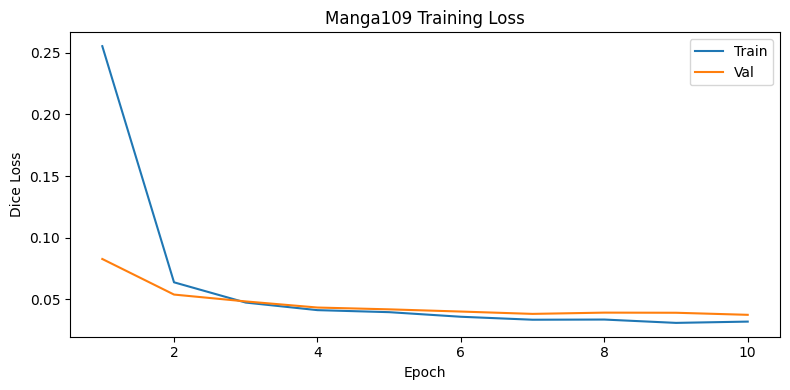

Saved to Drive.


In [ ]:
LOSSES_FILE = f'{PROJECT_DIR}/manga109_losses.json'

# Load from Drive if not in memory
if 'train_losses' not in dir() or len(train_losses) == 0:
    with open(LOSSES_FILE) as f:
        losses = json.load(f)
    train_losses = losses['train']
    val_losses   = losses['val']
    print('Loaded losses from Drive.')

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(train_losses)+1), train_losses, label='Train')
plt.plot(range(1, len(val_losses)+1),   val_losses,   label='Val')
plt.xlabel('Epoch')
plt.ylabel('Dice Loss')
plt.title('Manga109 Training Loss')
plt.legend()
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/manga109_loss_curve.png', dpi=150)
plt.show()
print('Saved to Drive.')


## Step 9 — Evaluate (F1 score)
Requires: Steps 0, 1, 2, 5, 7 to have been run this session.

In [ ]:
print('Paper (Dubray & Laubrock) reports F1 of 0.94')
for t in [0.3, 0.5, 0.7]:
    compute_f1(model, valloader, threshold=t)


Paper (Dubray & Laubrock) reports F1 of 0.94


Evaluating: 100%|██████████| 252/252 [04:50<00:00,  1.15s/it]


Threshold 0.30 | Precision 0.9728 | Recall 0.9555 | F1 0.9641


Evaluating: 100%|██████████| 252/252 [04:46<00:00,  1.14s/it]


Threshold 0.50 | Precision 0.9743 | Recall 0.9541 | F1 0.9641


Evaluating: 100%|██████████| 252/252 [04:45<00:00,  1.13s/it]

Threshold 0.70 | Precision 0.9757 | Recall 0.9526 | F1 0.9640


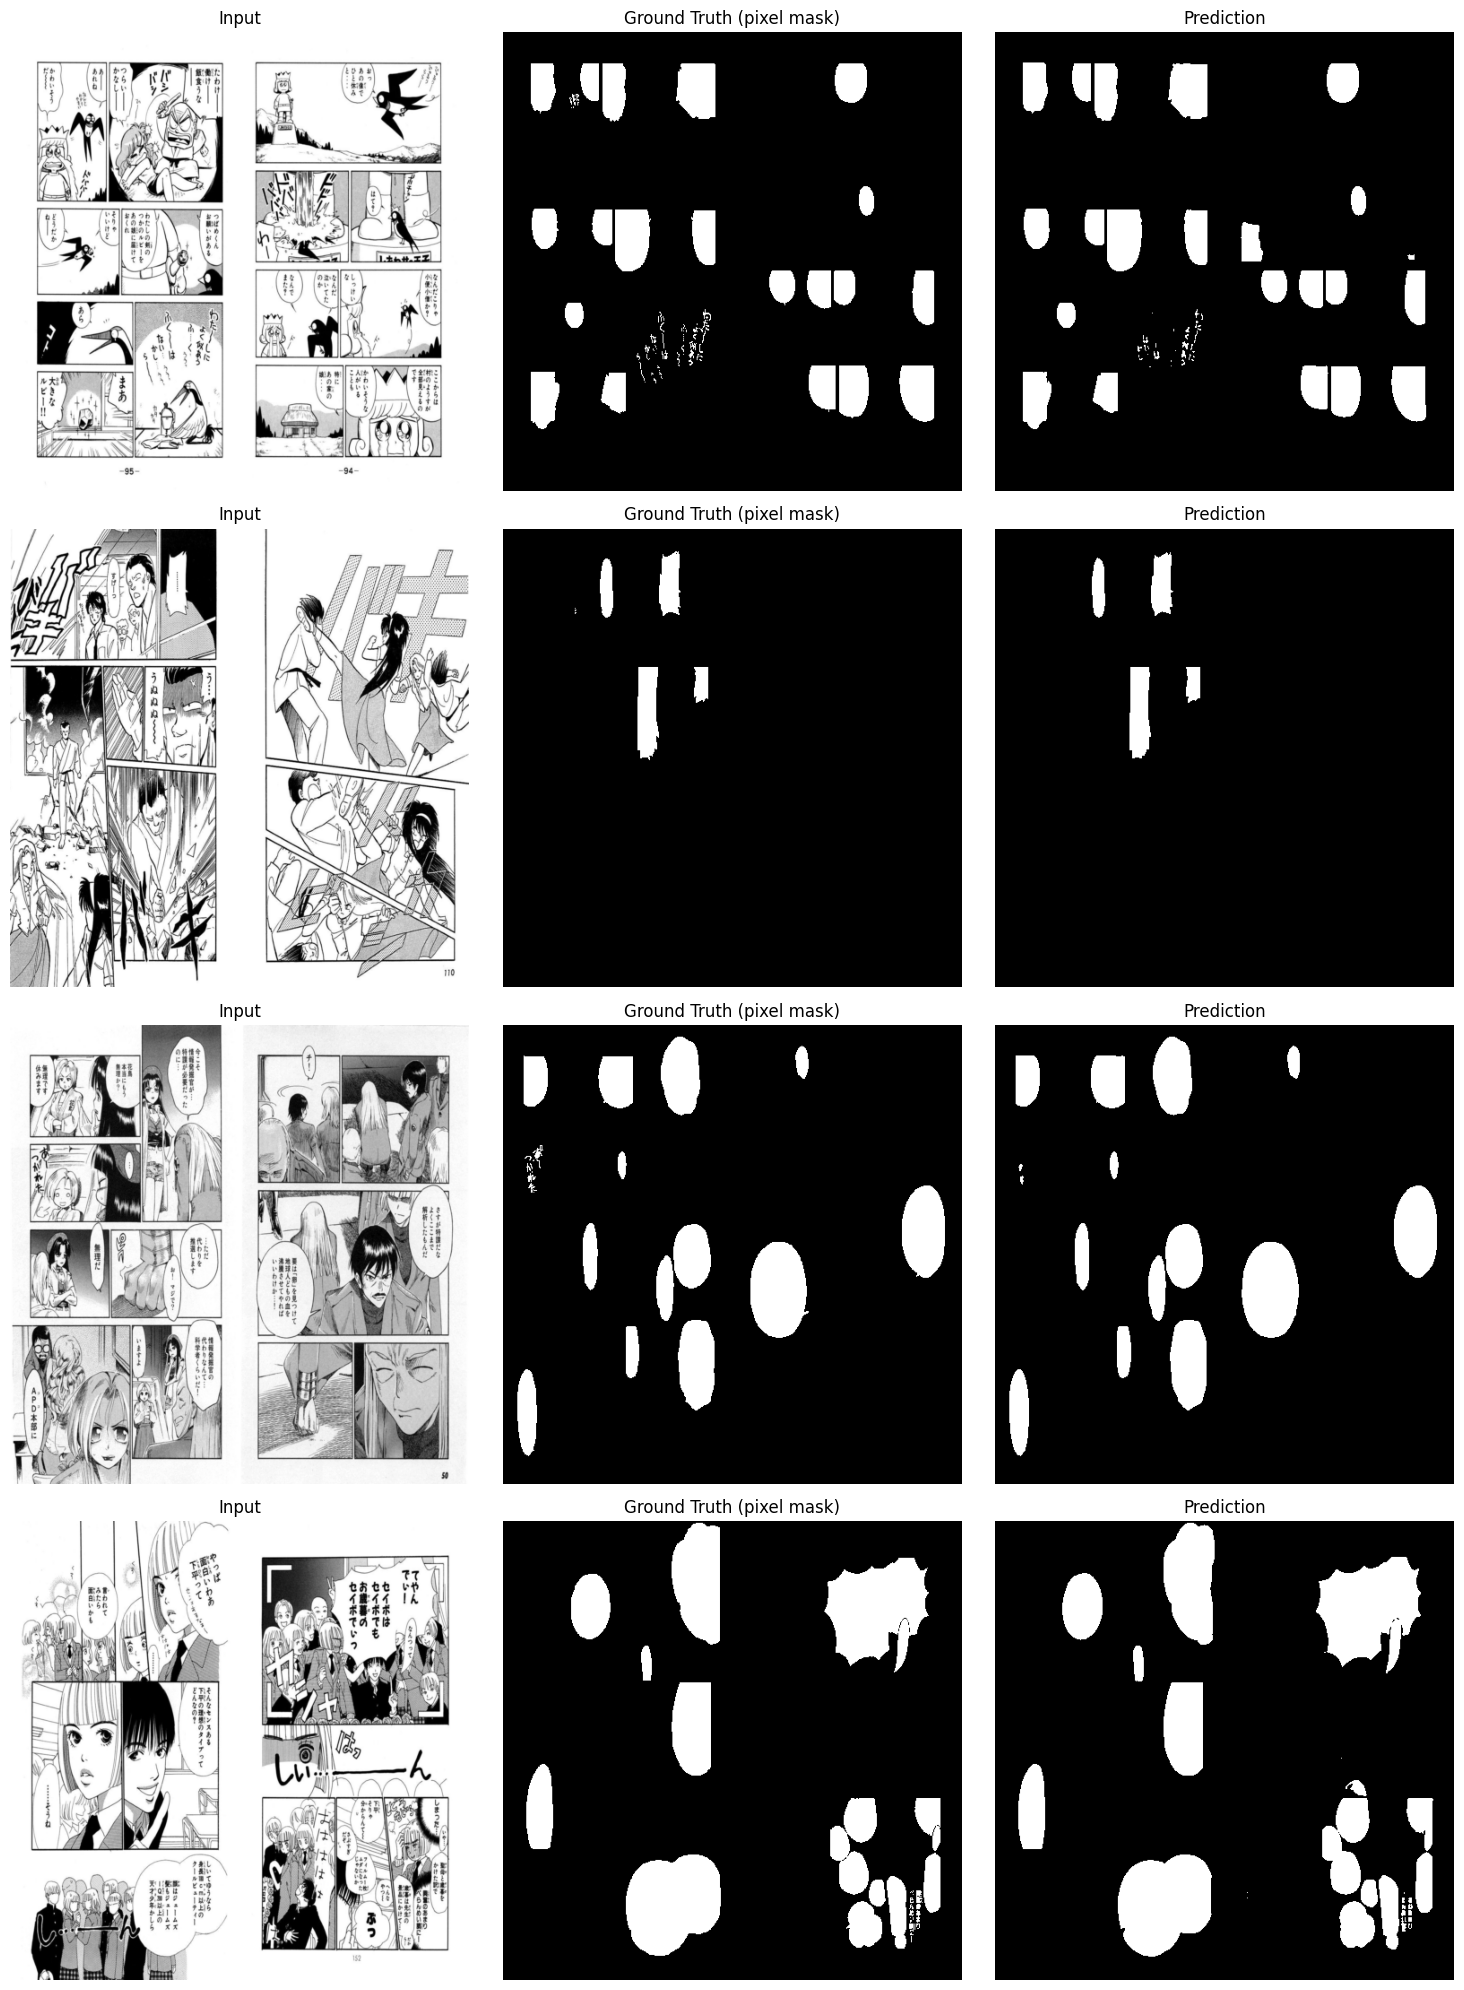

Saved to Drive.


In [ ]:
# Visualize predictions vs ground truth — save for report
model.eval()
fig, axes = plt.subplots(4, 3, figsize=(15, 20))
for i in range(4):
    img_t, mask_t = val_ds[i+4]
    with torch.no_grad():
        pred = torch.sigmoid(model(img_t.unsqueeze(0).to(device)))
    pred_bin = (pred.squeeze().cpu().numpy() > THRESHOLD).astype(np.uint8)

    axes[i, 0].imshow(img_t.squeeze(), cmap='gray')
    axes[i, 0].set_title('Input')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(mask_t.squeeze(), cmap='gray')
    axes[i, 1].set_title('Ground Truth (pixel mask)')
    axes[i, 1].axis('off')
    axes[i, 2].imshow(pred_bin, cmap='gray')
    axes[i, 2].set_title('Prediction')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/manga109_predictions.png', dpi=150)
plt.show()
print('Saved to Drive.')


## Step 10 — Run on your own manga page
Upload any manga page using the folder icon in the left sidebar.
Requires: Steps 0, 1, 2, 7 to have been run this session.

In [7]:
# Put your manga pages in this folder on Drive
INPUT_DIR = f'{PROJECT_DIR}/test_images'
os.makedirs(INPUT_DIR, exist_ok=True)

image_files = [f for f in os.listdir(INPUT_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

if not image_files:
    print(f'No images found in {INPUT_DIR}')
    print('Upload manga pages to that folder on Drive first.')
else:
    print(f'Found {len(image_files)} images, running pipeline...')
    for fname in image_files:
        img_path = f'{INPUT_DIR}/{fname}'
        pil_img  = Image.open(img_path)
        annotated, boxes = run_pipeline(pil_img, model)

        out_path = f'{PROJECT_DIR}/test_outputs/{fname}'
        os.makedirs(f'{PROJECT_DIR}/test_outputs', exist_ok=True)
        annotated.save(out_path)
        print(f'{fname}: detected {len(boxes)} balloons → saved')

        fig, axes = plt.subplots(1, 2, figsize=(16, 10))
        axes[0].imshow(pil_img, cmap='gray')
        axes[0].set_title('Original')
        axes[0].axis('off')
        axes[1].imshow(annotated)
        axes[1].set_title(f'Detected ({len(boxes)} balloons)')
        axes[1].axis('off')
        plt.tight_layout()
        plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Step 11 — OCR and translation (optional)
Adds Japanese OCR and English translation on top of the balloon detection.
manga-ocr model downloads ~400MB on first run.

In [8]:
from manga_ocr import MangaOcr
from deep_translator import GoogleTranslator

print('Loading manga-ocr...')
ocr = MangaOcr()
translator = GoogleTranslator(source='ja', target='en')
print('Ready!')


2026-03-10 23:33:10.661 | INFO     | manga_ocr.ocr:__init__:16 - Loading OCR model from kha-white/manga-ocr-base


Loading manga-ocr...


preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie decoder.bert.embeddings.word_embeddings.weight to decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie decoder.cls.predictions.bias to decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
MangaOcrModel LOAD REPORT from: kha-white/manga-ocr-base
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
2026-03-10 23:33:24.195 | INFO     | manga_ocr.ocr:__i

model.safetensors:   0%|          | 0.00/444M [00:00<?, ?B/s]

2026-03-10 23:33:25.388 | INFO     | manga_ocr.ocr:__init__:35 - OCR ready


Ready!


In [9]:
import re

INPUT_DIR = f'{PROJECT_DIR}/test_images'
OUTPUT_DIR = f'{PROJECT_DIR}/test_translated'
os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

image_files = [f for f in os.listdir(INPUT_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

if not image_files:
    print(f'No images found in {INPUT_DIR}')
else:
    print(f'Found {len(image_files)} images, running pipeline...')
    for fname in image_files:
        img_path = f'{INPUT_DIR}/{fname}'
        pil_img  = Image.open(img_path)
        img_gray = pil_img.convert('L')
        annotated, boxes = run_pipeline(pil_img, model)
        img_cv = cv2.cvtColor(np.array(pil_img.convert('RGB')), cv2.COLOR_RGB2BGR)

        for i, (x, y, w, h) in enumerate(boxes):
            crop = img_gray.crop((x, y, x+w, y+h))
            ja = ocr(crop)
            if not ja.strip():
                continue
            try:
                res = translator.translate(ja)
                en = str(res.text) if hasattr(res, 'text') else str(res)
            except Exception:
                en = str(ja)
            print(ja, en)
            en = en.replace('．', '.')
            if not en:
                continue

            roi = np.array(pil_img.convert('L'))[y:y+h, x:x+w]
            _, mask = cv2.threshold(roi, 200, 255, cv2.THRESH_BINARY)
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            if contours:
                global_contours = [c + (x, y) for c in contours]
                cv2.drawContours(img_cv, global_contours, -1, (255, 255, 255), -1)
            else:
                cv2.rectangle(img_cv, (x, y), (x+w, y+h), (255, 255, 255), -1)

            words = en.split()
            lines = []
            current = ''
            font = cv2.FONT_HERSHEY_SIMPLEX
            font_scale = min(w, h) / 200
            font_scale = max(0.4, min(font_scale, 1.2))
            thickness = 1

            for word in words:
                test = current + ' ' + word if current else word
                (tw, _), _ = cv2.getTextSize(test, font, font_scale, thickness)
                if tw > w - 10:
                    lines.append(current)
                    current = word
                else:
                    current = test
            if current:
                lines.append(current)

            line_height = int(font_scale * 30)
            total_height = len(lines) * line_height
            y_start = y + (h - total_height) // 2 + line_height

            for line in lines:
                (tw, _), _ = cv2.getTextSize(line, font, font_scale, thickness)
                x_start = x + (w - tw) // 2
                cv2.putText(img_cv, line, (x_start, y_start), font, font_scale, (0,0,0), thickness, cv2.LINE_AA)
                y_start += line_height

        result = Image.fromarray(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
        result.save(f'{OUTPUT_DIR}/{fname}')
        print(f'{fname}: processed {len(boxes)} balloons → saved')

        fig, axes = plt.subplots(1, 2, figsize=(16, 10))
        axes[0].imshow(pil_img, cmap='gray')
        axes[0].set_title('Original')
        axes[0].axis('off')
        axes[1].imshow(result)
        axes[1].set_title(f'Translated ({fname})')
        axes[1].axis('off')
        plt.tight_layout()
        plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Step 12 — Download results for report
Everything is already on Drive. This downloads to your local machine.

In [ ]:
from google.colab import files

to_download = [
    'manga109_loss_curve.png',
    'manga109_predictions.png',
    'manga109_data_exploration.png',
    'my_test_output.png',
    'my_translated_output.png',
]

for fname in to_download:
    path = f'{PROJECT_DIR}/{fname}'
    if os.path.exists(path):
        files.download(path)
        print(f'Downloaded {fname}')
    else:
        print(f'Not found yet: {fname}')
